# 4. From microstructure to properties: physics-anchored machine learning

Training data: 80 rows (33 grades x annealed / normalized / hot rolled). Every model is evaluated by
**leave-one-grade-out** cross-validation, so a grade is never seen in training when it is predicted. The
ladder runs from textbook equations, through composition-only ML, to the physics-anchored models.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
b = pd.read_csv(R / "s04_model_benchmark.csv")
b.pivot(index="model", columns="target", values="RMSE_inAD").round(1)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,2.8,17.6,45.4,43.9
anchored_gp,2.8,17.6,45.4,49.2
gated_ensemble,2.6,15.9,47.1,43.9
gbm_comp,3.1,24.6,86.9,62.2
gp_comp,2.5,19.9,63.1,53.7
gp_hybrid,2.7,17.3,55,55.4
gp_phys,2.7,20.3,52.5,43.5
greybox,4.2,27.2,92.3,62.6
greybox_gp,3.1,18.8,57,56.8


In [3]:
b.pivot(index="model", columns="target", values="R2_inAD").round(3)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,0.825,0.9,0.945,0.862
anchored_gp,0.825,0.9,0.945,0.827
gated_ensemble,0.854,0.919,0.941,0.863
gbm_comp,0.787,0.806,0.799,0.724
gp_comp,0.866,0.873,0.894,0.794
gp_hybrid,0.838,0.903,0.919,0.781
gp_phys,0.839,0.868,0.927,0.865
greybox,0.613,0.762,0.773,0.72
greybox_gp,0.791,0.887,0.913,0.77


Accuracy on the **change** from annealed to normalized - the what-if this project is about:

In [4]:
b.pivot(index="model", columns="target", values="delta_RMSE").round(1)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,3.6,24.6,64.9,53.5
anchored_gp,3.6,24.6,64.9,48.3
gated_ensemble,3.4,20.2,68.9,56
gbm_comp,3.6,27.7,99.4,69.7
gp_comp,3.1,22.1,79.4,62.7
gp_hybrid,3.6,20.1,78.6,74.6
gp_phys,3.5,26,74.4,59.5
greybox,5.1,29.7,106,58.9
greybox_gp,4,22.5,77.1,54.6


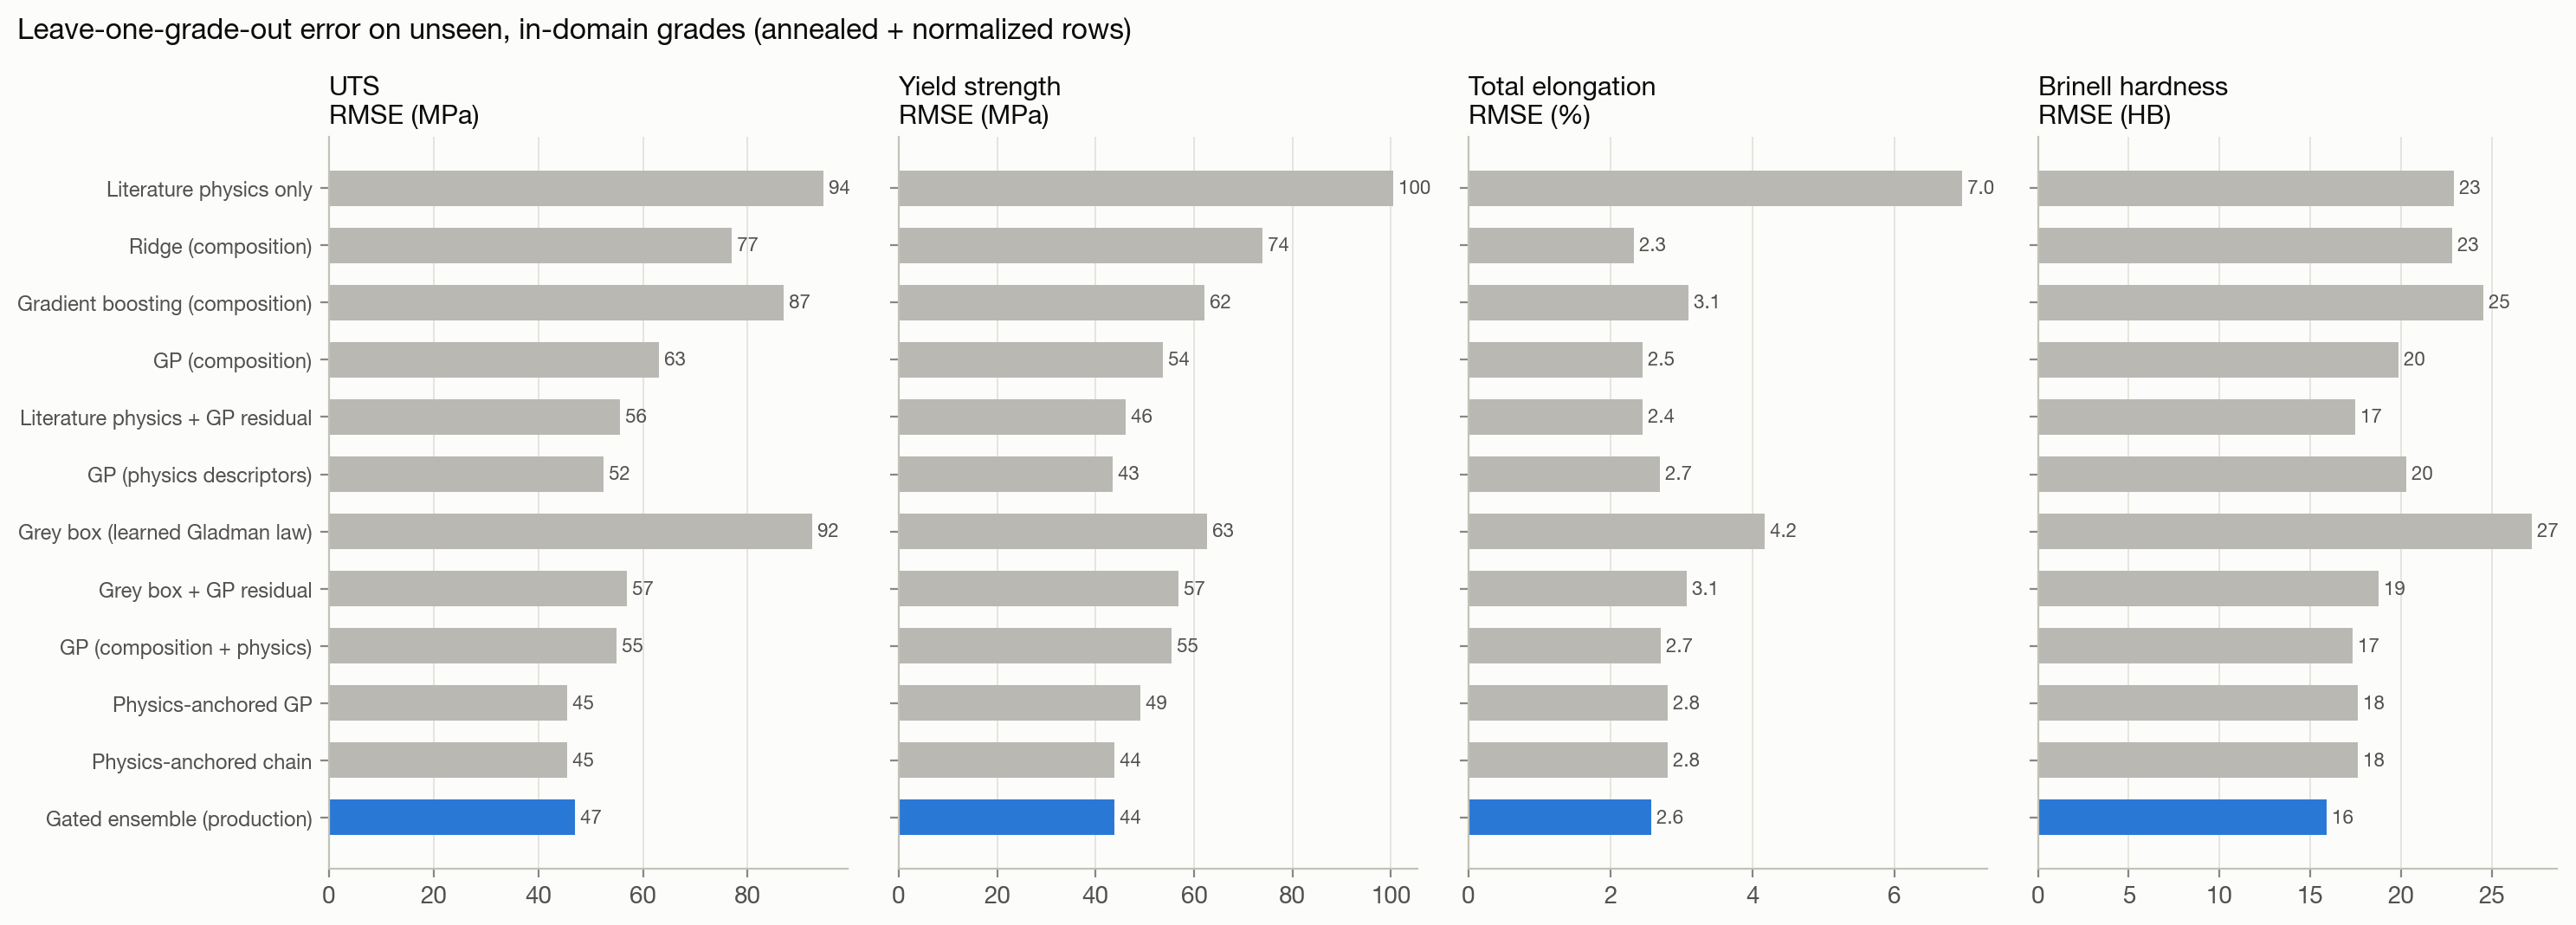

In [5]:
fig("fig12_model_ladder")

## Are the differences real? Paired tests against the production model
Per-grade errors, Wilcoxon signed-rank test (with the Holm adjustment for the eleven comparisons per property)
and a bootstrap 95 % interval of the RMSE difference (positive = the other model is worse).

In [6]:
pd.read_csv(R / "s04_paired_tests.csv").round(3)

,target,model,RMSE_minus_production,CI95_lo,CI95_hi,wilcoxon_p,n_grades,wilcoxon_p_holm
0,UTS_MPa,physics_lit,47.4,25.5,67.6,0,27,0.001
1,UTS_MPa,ridge_comp,29.9,9.97,47.3,0.013,27,0.097
2,UTS_MPa,gbm_comp,39.8,17.9,59.6,0.003,27,0.027
3,UTS_MPa,gp_comp,16,1.7,30.5,0.062,27,0.309
4,UTS_MPa,physlit_gp,8.52,1.01,15.7,0.22,27,0.879
5,UTS_MPa,gp_phys,5.43,-7.97,17.4,0.628,27,1
6,UTS_MPa,greybox,45.3,31.1,58.5,0,27,0
7,UTS_MPa,greybox_gp,9.91,2.92,16.7,0.012,27,0.097
8,UTS_MPa,gp_hybrid,7.92,0.409,14.5,0.019,27,0.112
9,UTS_MPa,anchored_gp,-1.63,-6.51,3.81,0.768,27,1


## Uncertainty: normalised conformal intervals
The ensemble's own error bars are only roughly calibrated (a Gaussian 90 % interval would use 1.645 standard
deviations; the factors below range from about 1.5 to 2.1). Normalised split-conformal calibration rescales them
so that the intervals cover 90 % of unseen grades, and that coverage is checked here.

In [7]:
pd.read_csv(R / "s04_conformal.csv")

,target,q90_normalised,LOGO_coverage_90,mean_interval_width
0,UTS_MPa,1.69,0.925,155
1,YS_MPa,1.47,0.925,133
2,El_pct,2.13,0.925,8.33
3,HB,1.62,0.925,51.9


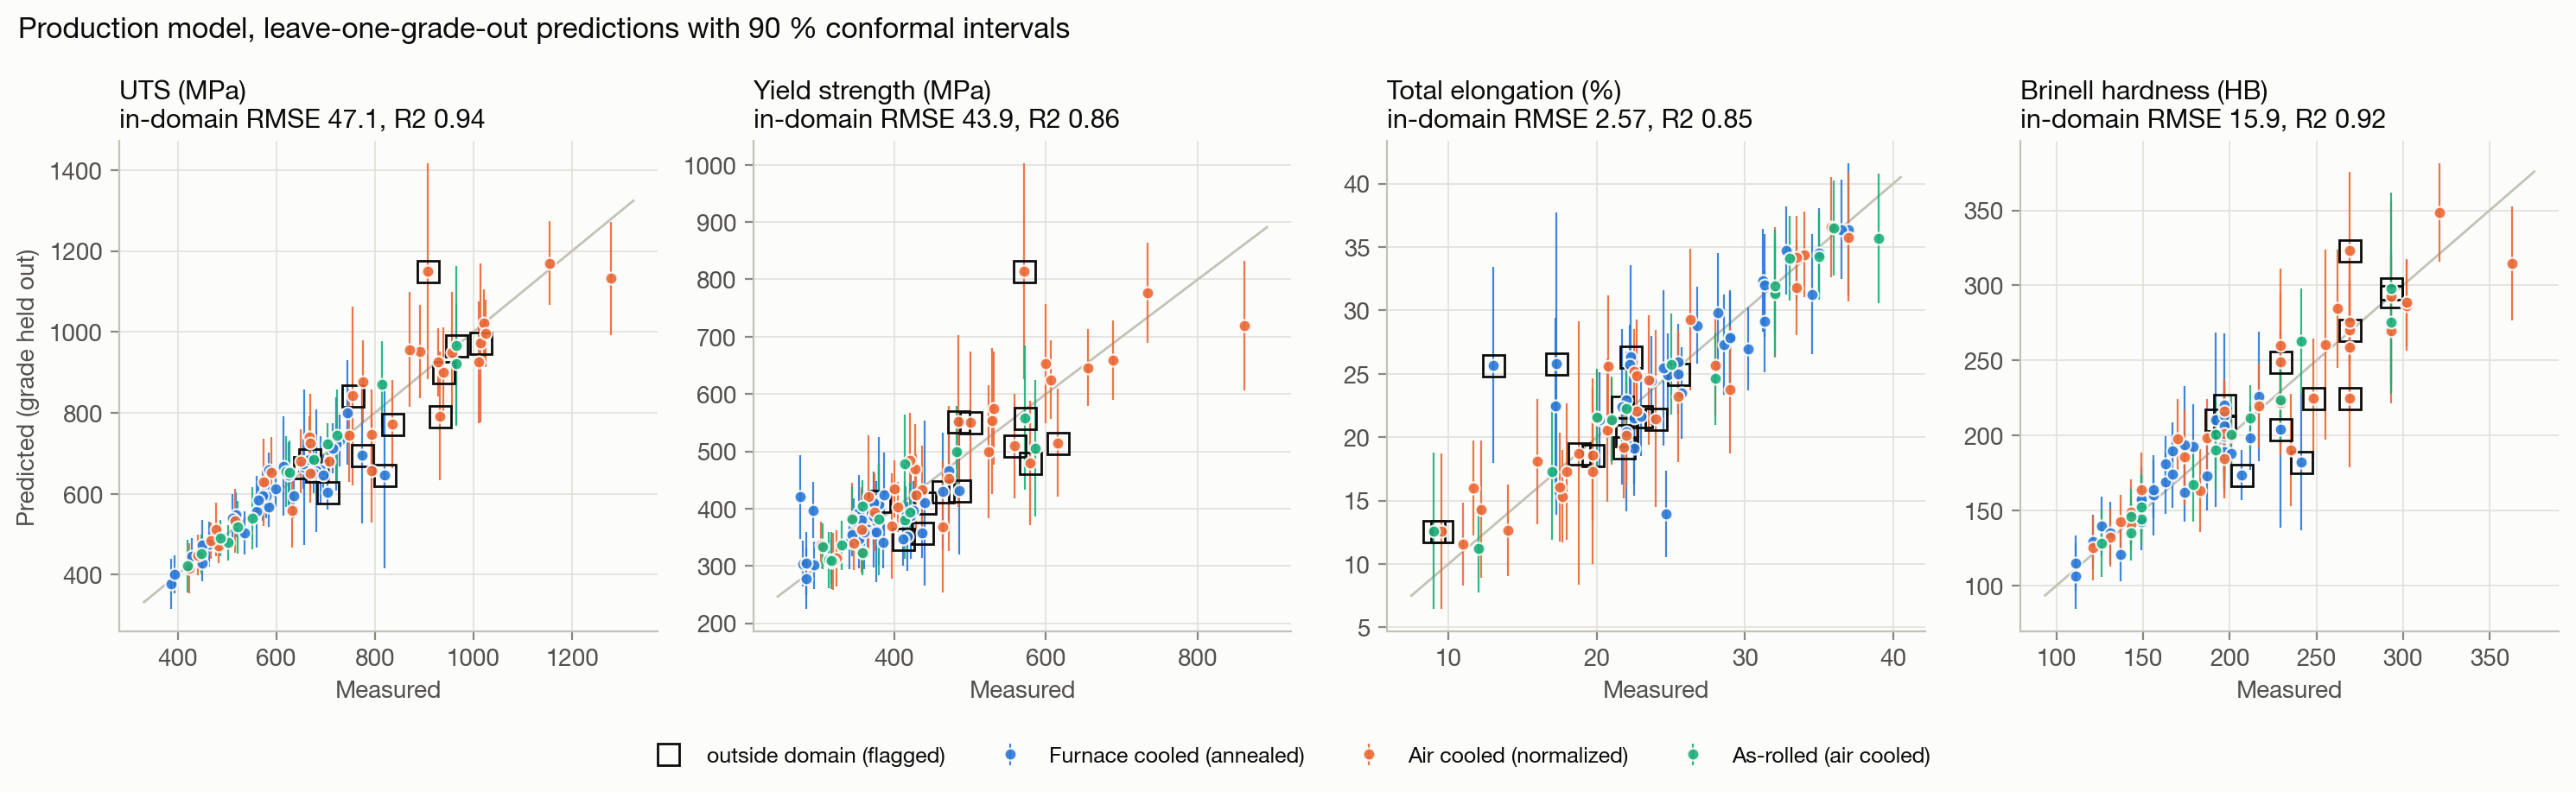

In [8]:
fig("fig13_parity_production")

## The decisive test: cooling rates the training data never contain
Models trained only on annealed/normalised data predict the measured hardness of three steels cooled at
0.1-50 K/s. ML without physics cannot invent the hardness of bainite or martensite; the physics-anchored
production model inherits it from the transformation model.

In [9]:
pd.read_csv(R / "s04_cooling_rate_extrapolation.csv").round(1)

,model,HB_RMSE_EN3B,HB_RMSE_EN8,HB_RMSE_SA540,HB_RMSE_rates_le_5Ks,HB_RMSE_all
0,physics_lit,23.9,77.5,85.6,56.8,68.1
1,ridge_comp,16.2,20.7,263,138,152
2,gbm_comp,39.5,45.1,280,147,166
3,gp_comp,20,29,219,110,128
4,physlit_gp,23.8,77.8,84.5,56.1,67.7
5,gp_phys,20,9.2,210,103,122
6,greybox,24.7,61.5,142,86.7,90.7
7,greybox_gp,14.3,64,120,69.3,78.9
8,gp_hybrid,25.9,23.3,226,113,132
9,anchored_gp,21,39.5,69.9,47.9,47.9


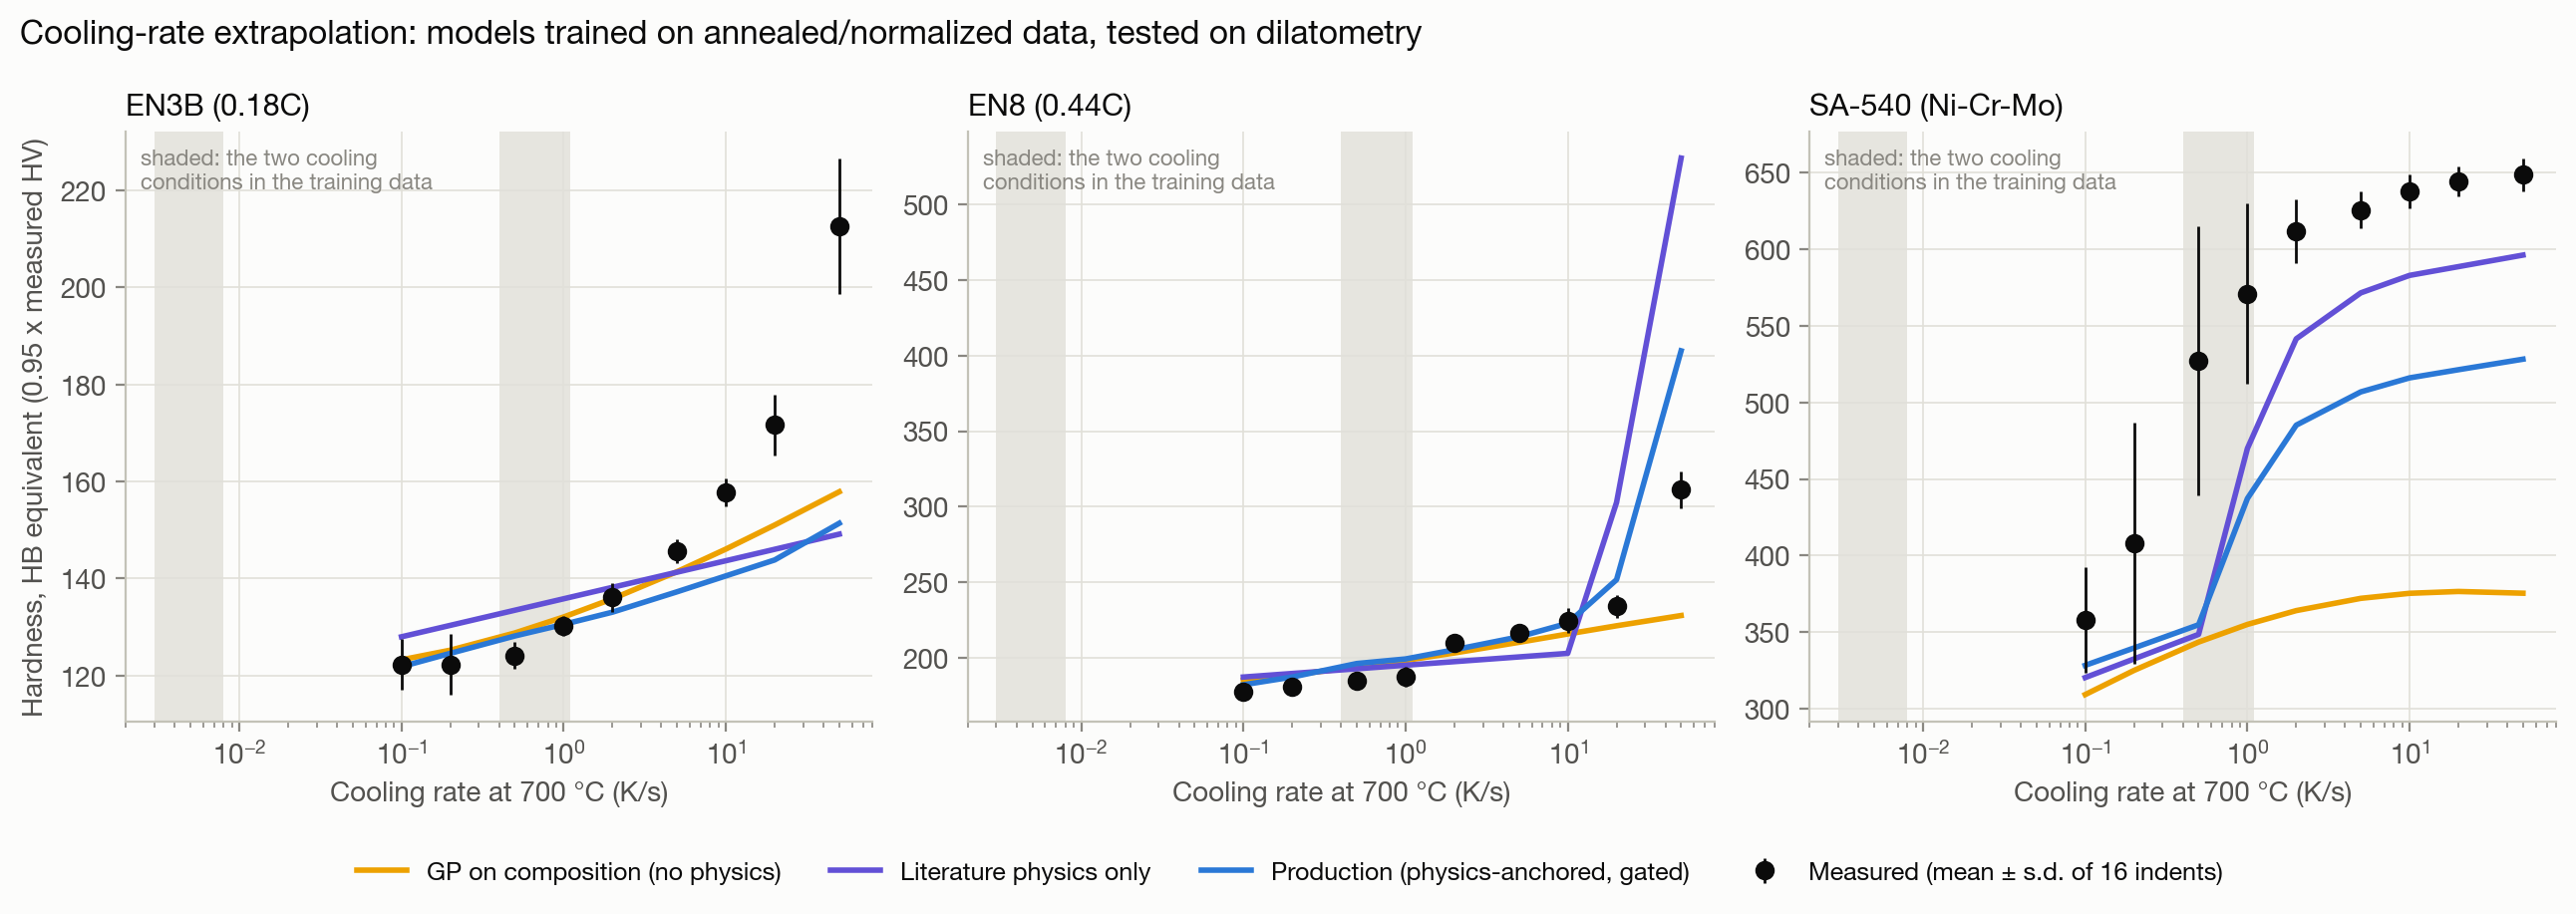

In [10]:
fig("fig14_cooling_rate_extrapolation")

## Physical consistency and interpretability
Share of cooling-rate steps where a property moves the wrong way, and the span of the predicted UTS / HB
over a normal 0.10-0.40 % Si (physically a few tens of MPa).

In [11]:
c = pd.read_csv(R / "s04_consistency.csv")
c.pivot(index="model", columns="target", values="rate_violation_frac").round(3)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,0.109,0.045,0.04,0.068
anchored_gp,0.109,0.045,0.04,0.068
gated_ensemble,0.008,0.02,0.005,0.038
gbm_comp,0,0,0,0
gp_comp,0,0,0,0.003
gp_hybrid,0,0.028,0.01,0.189
gp_phys,0,0.028,0.033,0.066
greybox,0.02,0.008,0.008,0.008
greybox_gp,0.109,0.045,0.061,0.013


In [12]:
c.pivot(index="model", columns="target", values="si_0.10_0.40_span").round(1)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,1.1,11.7,41.7,28.5
anchored_gp,1.1,11.7,41.7,22.9
gated_ensemble,0.4,8,26.3,20.6
gbm_comp,0.2,4.1,9.9,28.1
gp_comp,0,0.7,11.2,3.5
gp_hybrid,0.1,3,16.8,10.7
gp_phys,0.1,5.4,33.4,11.3
greybox,0.6,6.9,23.8,19.4
greybox_gp,0.8,8.1,30.3,19.4


## Two lessons, kept as ablations
**Silicon.** Every training grade has the same nominal Si (0.225 % carbon grades, 0.25 % alloy H-grades)
except 9255. With Si as an input, cross-validation looks better because Si labels the grade type, but the
response to a real change of Si is unphysical. Si and V are therefore left to the physics.

In [13]:
pd.read_csv(R / "s04_silicon_ablation.csv").round(1)

,silicon_input,model,UTS_RMSE_inAD,UTS_RMSE_outAD,UTS_span_Si_0.10_to_0.40
0,False,gp_comp,63.1,85.4,11.2
1,False,gated_ensemble,47.1,108,26.3
2,True,gp_comp,57.9,98.9,27.3
3,True,gated_ensemble,51.2,118,264


**The gate.** Handing over to the physics-anchored members for every unfamiliar composition, or above
the fastest training cooling rate, was tried first; this table re-scores those rules on the same evidence.

In [14]:
pd.read_csv(R / "s04_gate_ablation.csv").set_index("rule").T.round(3)

rule,final: hard phase + martensite,final + composition gate,final + cooling-rate gate,first version: composition + rate + hard phase
UTS_MPa_RMSE_outAD,108,109,108,109
UTS_MPa_RMSE_inAD,47.1,47.1,47.1,47.1
UTS_MPa_check_vs_production,0,NaN,NaN,NaN
YS_MPa_RMSE_outAD,93.8,88,93.8,88
YS_MPa_RMSE_inAD,43.9,43.9,43.9,43.9
YS_MPa_check_vs_production,0,NaN,NaN,NaN
El_pct_RMSE_outAD,4.82,4.93,4.82,4.93
El_pct_RMSE_inAD,2.57,2.57,2.57,2.57
El_pct_check_vs_production,0,NaN,NaN,NaN
HB_RMSE_outAD,31.6,32.4,31.6,32.4


**The physics anchor.** The anchored models first scaled every property on the Maynier hardness, whose
ferrite-pearlite term depends on composition and cooling rate only and cannot see pearlite refinement. They
now scale on the Gladman law (ferrite fraction, grain size, spacing) for ferrite + pearlite and on Maynier
for bainite and martensite. Inside the data this costs a few MPa; at new cooling rates and for new
compositions it is clearly better.

In [15]:
pd.read_csv(R / "s04_anchor_ablation.csv").set_index("anchor").T.round(3)

anchor,"Maynier hardness, all constituents (first version)","Gladman law for F+P, Maynier for B+M (production)"
UTS_MPa_RMSE_inAD,48.3,47.1
UTS_MPa_RMSE_outAD,114,108
UTS_MPa_change_RMSE,69.2,68.9
YS_MPa_RMSE_inAD,46.6,43.9
YS_MPa_RMSE_outAD,92.7,93.8
YS_MPa_change_RMSE,60.4,56
El_pct_RMSE_inAD,2.59,2.57
El_pct_RMSE_outAD,4.65,4.82
El_pct_change_RMSE,3.22,3.38
HB_RMSE_inAD,16.3,15.9


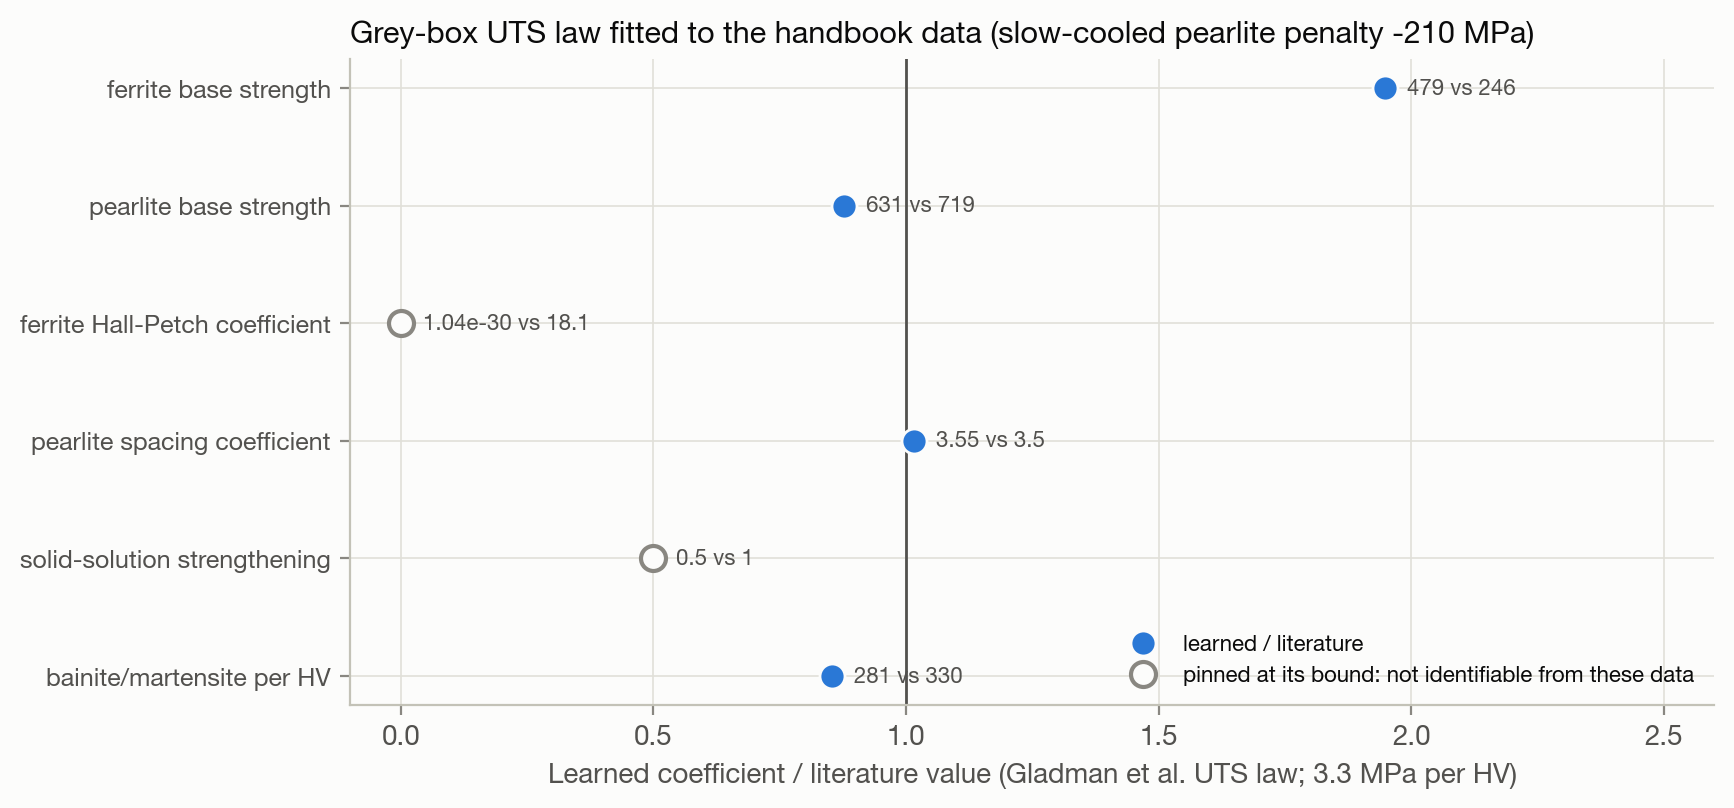

In [16]:
fig("fig15_greybox_coefficients", 800)